# The emg2pose pipeline, end to end: what goes in, what comes out, and where our bottleneck goes

A reference notebook: every array that flows through the benchmark, with its **shape, units
and sampling rate**, computed live from the data and from Meta's **pretrained checkpoint**.

1. The big picture
2. One recording: the raw arrays
3. The full dataset in numbers (metadata CSV): users, stages, hours, splits
4. Preprocessing: what is done before the network sees the data (spoiler: almost nothing)
5. The network, layer by layer (real checkpoint)
6. The output and the two metrics (angle MAE, landmark distance)
7. Running the pretrained model on the mini dataset (a held-out user)
8. Where our project plugs in: sEMG → latent z → pose

Data: `~/emg2pose_dataset_mini` (1 user, 15 tasks, both hands). Checkpoints: `~/emg2pose_model_checkpoints`
(downloaded automatically, ~250 MB).

## Setup

**Locally:** run `uv sync --extra cpu` in the repo root and pick the **semg2pose** kernel. The cell below does nothing.

**On Colab:** select *Runtime → Change runtime type → Runtime version 2026.07* (Python 3.12), optionally with a T4 GPU.
Run the cell below once; when it says so, do *Runtime → Restart session* and run the notebook from the top again.

In [1]:
# Colab only: clone semg2pose (with the emg2pose submodule) and install it. Locally this does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not (3, 10) <= sys.version_info[:2] < (3, 13):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime version 2026.07 "
                           "(Python 3.12), then run this cell again.")
    REPO_DIR = Path("/content/semg2pose")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/eljoserass/semg2pose.git", str(REPO_DIR)], check=True)
    try:
        import semg2pose  # noqa: F401  (installed in a previous run + restart)
        print("semg2pose is installed, continue.")
    except ImportError:
        subprocess.run(["bash", str(REPO_DIR / "scripts" / "colab_setup.sh")], check=True,
                       env={**os.environ, "PYTHON": sys.executable})
        print("Installed. Now: Runtime > Restart session, then run the notebook from the top.")
else:
    print("Local kernel:", sys.executable)

Local kernel: /home/rodri/projects/emg2poseneuromatch/semg2pose/.venv/bin/python


In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import signal

from emg2pose.kinematics import forward_kinematics, load_default_hand_model
from emg2pose.constants import LANDMARKS, NO_MOVEMENT_LANDMARKS
from emg2pose.data import WindowedEmgDataset
from semg2pose.data import FS, JOINT_NAMES, download_mini_dataset, list_sessions, load_session, find_session
from semg2pose.model import download_checkpoints, download_metadata, load_pretrained, predict_session

warnings.filterwarnings("ignore")  # lightning / pkg_resources deprecation noise
DATASET_DIR = download_mini_dataset()
CKPT_DIR = download_checkpoints()
torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 100

Dataset already downloaded: /home/rodri/emg2pose_dataset_mini
Checkpoints already downloaded: /home/rodri/emg2pose_model_checkpoints


## 1. The big picture

```
 wristband (16 bipolar electrodes, 2 kHz)          motion capture (markers on the hand)
       │                                                     │  inverse kinematics (UmeTrack hand model)
       ▼                                                     ▼
 EMG  x(t) ∈ R^16  ──────────── same 2 kHz clock ──────────  joint angles y(t) ∈ R^20  (radians)
       │
       │  (device: 40 Hz high-pass, noise floor scaled to std 1;  dataset: nothing else)
       ▼
 window of 11,790 samples  =  1,790 context (0.9 s)  +  10,000 predicted (5 s)
       │
       ▼   network: learned conv filters + TDS blocks   (B, 16, 11790) → (B, 64, 125)   ~25 Hz features
       ▼   resample to 50 Hz                             (B, 64, 250)
       ▼   LSTM decoder, one step every 20 ms, fed [features(64) , previous pose(20)] = 84
       ▼   outputs a pose change (velocity) or a pose  → integrated → (B, 20, 250)
       ▼   upsampled back to 2 kHz                       (B, 20, 10000)
       ▼
 loss / metrics vs y(t):  angle MAE (°),  landmark distance (mm, via forward kinematics)
```

Two flavours of the same model are released:

| | **tracking** (`tracking_vemg2pose`) | **regression** (`regression_vemg2pose`) |
|---|---|---|
| knows the true pose at the start of the window? | **yes** (`provide_initial_pos=True`) | no |
| what the decoder outputs | a **velocity** (pose change per step) that is added to the previous pose | an absolute pose for the first 250 ms, then velocities |
| real-world meaning | "start from a calibrated pose and follow it" | "guess the pose from EMG alone" |

## 2. One recording: the raw arrays

In [3]:
sessions = list_sessions(DATASET_DIR)
path = find_session("HandClawGraspFlicks", "right", sessions)
emg, angles, ok, meta = load_session(path)

print(f"file: {path.name}")
print(f"emg          {emg.shape}  -> (time samples, 16 channels), {FS} Hz, {len(emg) / FS:.1f} s")
print(f"joint_angles {angles.shape}  -> (time samples, 20 angles), radians, same clock as the EMG")
print(f"tracking OK  {ok.mean():.1%} of samples (the rest are IK failures: all 20 angles = 0)")
print(f"EMG value range: median |x| = {np.median(np.abs(emg)):.2f}, 99.9th pct = {np.percentile(np.abs(emg), 99.9):.0f}"
      "  (units: multiples of the noise floor std)")
pd.Series(meta).drop(["filename"], errors="ignore").to_frame("metadata").T

file: 2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-10_right.hdf5
emg          (119266, 16)  -> (time samples, 16 channels), 2000 Hz, 59.6 s
joint_angles (119266, 20)  -> (time samples, 20 angles), radians, same clock as the EMG
tracking OK  87.9% of samples (the rest are IK failures: all 20 angles = 0)


EMG value range: median |x| = 9.86, 99.9th pct = 298  (units: multiples of the noise floor std)


,end,generalization,held_out_stage,held_out_user,moving_hand,num_channels,sample_rate,session,side,split,stage,start,user
metadata,1670313462.666667,user,False,True,both,16,2000.0,2022-12-06-1670313600-e3096-cv-emg-pose-train@2,right,val,HandClawGraspFlicks,1670313403.0,d387095792


**Data rate.** 16 EMG numbers every 0.5 ms (32,000 numbers per second) are mapped to 20 angles. The angles are
stored at 2 kHz too, but hands move slowly: almost all the pose information is below ~10 Hz, which is why the
model predicts at 50 Hz and simply interpolates up.

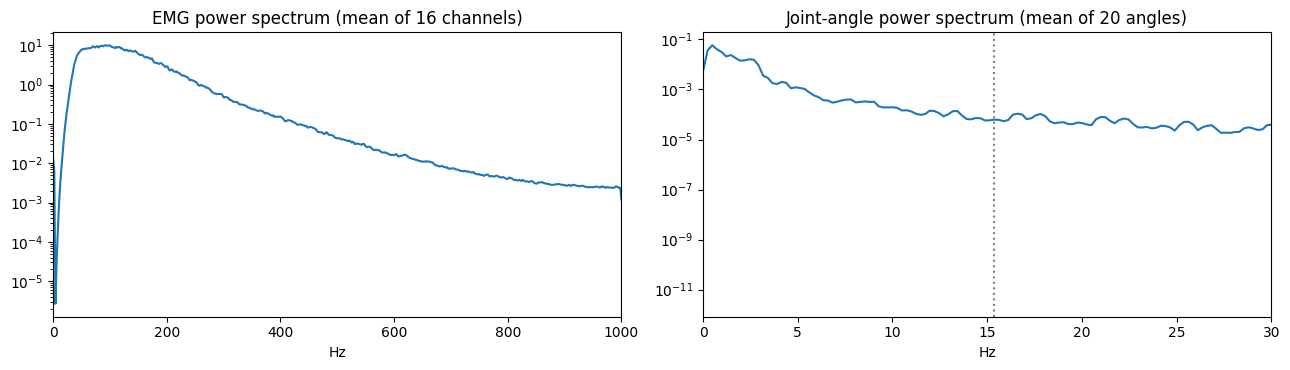

99 % of the joint-angle power is below 15.4 Hz; the EMG power is spread over ~40-500 Hz


In [4]:
f, P_ang = signal.welch(angles[ok], FS, nperseg=8192, axis=0)
f2, P_emg = signal.welch(emg, FS, nperseg=1024, axis=0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.semilogy(f2, P_emg.mean(1)); ax1.set_xlim(0, 1000)
ax1.set_title("EMG power spectrum (mean of 16 channels)"); ax1.set_xlabel("Hz")
ax2.semilogy(f, P_ang.mean(1)); ax2.set_xlim(0, 30)
ax2.set_title("Joint-angle power spectrum (mean of 20 angles)"); ax2.set_xlabel("Hz")
cum = np.cumsum(P_ang.mean(1)) / P_ang.mean(1).sum()
ax2.axvline(f[np.searchsorted(cum, 0.99)], color="gray", ls=":")
plt.tight_layout(); plt.show()
print(f"99 % of the joint-angle power is below {f[np.searchsorted(cum, 0.99)]:.1f} Hz; "
      f"the EMG power is spread over ~40-500 Hz")

## 3. The full dataset in numbers

The mini dataset is a single user. The project will use the full dataset (431 GiB), whose index is a small
CSV: one row per recording (one hand, one stage).

In [5]:
md = pd.read_csv(download_metadata())
md["minutes"] = (md["end"] - md["start"]) / 60
print(f"{len(md)} recordings, {md.user.nunique()} users, {md.session.nunique()} sessions, "
      f"{md.stage.nunique()} stages, {md.minutes.sum() / 60:.0f} hours (both hands counted separately)")
summary = md.groupby(["split", "generalization"]).agg(recordings=("filename", "size"), users=("user", "nunique"),
                                                      stages=("stage", "nunique"), hours=("minutes", lambda m: m.sum() / 60))
summary.round(1)

25253 recordings, 193 users, 751 sessions, 29 stages, 424 hours (both hands counted separately)


recordings  users  stages  hours
split generalization                                  
test  stage                 3539    158       6   58.8
      user                  2172     20      23   36.4
      user_stage             456     20       6    7.5
train none                 17136    158      23  288.9
val   user                  1618     15      23   27.2
      user_stage             332     15       6    5.4

**How to read the splits.** `train` users and stages are seen during training. Validation/test hold out
**users** (`user`: new person, known stages), **stages** (`stage`: known people, new movements), or **both**
(`user_stage`). These are the three generalisation conditions of the proposal.

Our mini user (`d387095792`) is a **validation, held-out user**: the pretrained checkpoints have never seen them.
Four of their stages are also held-out stages (`user_stage`).

In [6]:
mini = md[md.filename.isin([p.stem for p in sessions.path])]
mini.groupby(["stage"]).first()[["user", "split", "generalization"]]

,user,split,generalization
stage,,,
CountingUpDownFaceSideAway,d387095792,val,user_stage
FingerAbductionSeries,d387095792,val,user
FingerFreeform,d387095792,val,user_stage
FingerPinchesSingleFingerPinchesMultiple,d387095792,val,user
FingerWigglingSpreading,d387095792,val,user
HandClawGraspFlicks,d387095792,val,user
HookEmHornsOKScissors,d387095792,val,user_stage
IndividualFingerPointingSnap,d387095792,val,user
OneHandedFreeStyle,d387095792,val,user


## 4. Preprocessing: what happens before the network

| step | where | what |
|---|---|---|
| analog front end + 40 Hz high-pass | device | removes motion artefacts and DC drift |
| scaling so the noise floor has std 1 | dataset | makes channels/users comparable in amplitude |
| left hand sign flip | dataset | the left band has reversed electrode polarity |
| windowing: 11,790-sample windows inside IK-failure-free blocks | `WindowedEmgDataset(skip_ik_failures=True)` | the first 1,790 samples are context only (the conv receptive field) |
| random jitter of the window start | train only | data augmentation |
| `RotationAugmentation`: roll the 16 channels by −1, 0 or +1 | train only | simulates the band being worn slightly rotated |
| `ExtractToTensor` | always | takes the `emg` field as a float tensor, (channels, time) |

**There is no hand-made feature extraction**: no band-pass, no rectification, no envelope, no FFT. The raw 2 kHz
signal goes into the network, and the first convolution learns its own filters (see
`spectral_spatial_fingerprints.ipynb` section 5 for what it learned).

1 windows in this recording; one window:
  emg                (16, 11790)
  joint_angles       (20, 11790)
  no_ik_failure      (11790,)
  window_start_idx   79267
  window_end_idx     91057


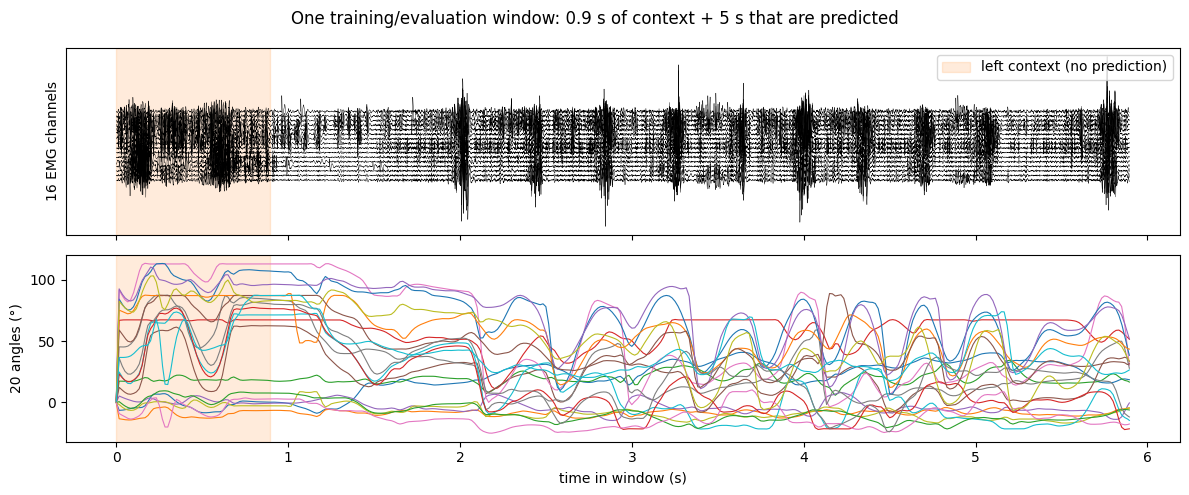

In [7]:
ds = WindowedEmgDataset(path, window_length=11_790, skip_ik_failures=True)
w = ds[0]
print(f"{len(ds)} windows in this recording; one window:")
for k, v in w.items():
    print(f"  {k:18s} {tuple(v.shape) if hasattr(v, 'shape') and v.ndim else v}")

t_w = np.arange(w["emg"].shape[1]) / FS
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for c in range(16):
    ax1.plot(t_w, w["emg"][c].numpy() + 40 * c, lw=0.3, color="k")
ax1.axvspan(0, 1790 / FS, color="tab:orange", alpha=0.15, label="left context (no prediction)")
ax1.set_yticks([]); ax1.set_ylabel("16 EMG channels"); ax1.legend(loc="upper right")
ax2.plot(t_w, np.degrees(w["joint_angles"].numpy().T), lw=0.8)
ax2.axvspan(0, 1790 / FS, color="tab:orange", alpha=0.15)
ax2.set_ylabel("20 angles (°)"); ax2.set_xlabel("time in window (s)")
fig.suptitle("One training/evaluation window: 0.9 s of context + 5 s that are predicted")
plt.tight_layout(); plt.show()

## 5. The network, layer by layer

We load the pretrained **tracking** checkpoint and push one window through it, printing the shape after every
block. Time resolution = how many EMG samples one output step summarises.

In [8]:
module = load_pretrained("tracking_vemg2pose", CKPT_DIR)
net = module.model.network
x = w["emg"][None].float()
rows = [{"block": "input (raw EMG)", "shape (B, C, T)": tuple(x.shape), "rate (Hz)": FS, "params": 0}]
stride = 1
with torch.no_grad():
    for name, layer in net.layers.named_children():
        x = layer(x)
        stride *= layer.stride if hasattr(layer, "stride") else layer.layers.conv1dblock.stride
        rows.append({"block": f"{name}: {type(layer).__name__}", "shape (B, C, T)": tuple(x.shape),
                     "rate (Hz)": FS / stride, "params": sum(p.numel() for p in layer.parameters())})
dec = module.model.decoder
rows.append({"block": "resample to 50 Hz (interpolate)", "shape (B, C, T)": (1, x.shape[1], 250), "rate (Hz)": 50, "params": 0})
rows.append({"block": "LSTM decoder: in 64 + 20 (prev. pose) = 84, hidden 512 x 2 layers",
             "shape (B, C, T)": (1, 20, 250), "rate (Hz)": 50, "params": sum(p.numel() for p in dec.parameters())})
rows.append({"block": "upsample to 2 kHz (interpolate)", "shape (B, C, T)": (1, 20, 10_000), "rate (Hz)": FS, "params": 0})
layers = pd.DataFrame(rows)
print(f"left context (receptive field) = {net.left_context} samples = {net.left_context / FS * 1000:.0f} ms")
print(f"total parameters: {sum(p.numel() for p in module.parameters()) / 1e6:.2f} M")
layers

Lightning automatically upgraded your loaded checkpoint from v1.8.6 to v2.2.2. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint ../../../../emg2pose_model_checkpoints/tracking_vemg2pose.ckpt`


left context (receptive field) = 1790 samples = 895 ms
total parameters: 5.97 M


,block,"shape (B, C, T)",rate (Hz),params
0,input (raw EMG),"(1, 16, 11790)",2000.0,0
1,0: Conv1dBlock,"(1, 256, 2356)",400.0,45824
2,1: Conv1dBlock,"(1, 256, 1176)",200.0,328448
3,2: TdsStage,"(1, 256, 274)",50.0,1384736
4,3: TdsStage,"(1, 64, 125)",25.0,874848
5,resample to 50 Hz (interpolate),"(1, 64, 250)",50.0,0
6,"LSTM decoder: in 64 + 20 (prev. pose) = 84, hi...","(1, 20, 250)",50.0,3336212
7,upsample to 2 kHz (interpolate),"(1, 20, 10000)",2000.0,0


(Rate = 2000 Hz divided by the accumulated stride. Each block also trims its kernel width from the start, which
is why the 11,790 input samples end as 125 steps: exactly the 5 s predicted span at **25 Hz**.)

**Reading it.**
- `0: Conv1dBlock`: **256 learned filters, each 16 channels × 11 samples (5.5 ms)**, stride 5. This single layer
  replaces all hand-made spatial and spectral feature engineering.
- The strided convolutions take 2 kHz down to ~25 Hz in four steps, while widening each step's view: one output
  step "sees" the last ~0.9 s of EMG.
- The decoder runs at 50 Hz and is **autoregressive**: each step receives the pose it predicted in the previous
  step. That is why knowing the starting pose (tracking) helps so much.
- The **64-number feature vector** at 25 Hz is the network's internal "EMG representation". Our bottleneck lives
  on the other side, in the 20-number **pose** output.

## 6. The output and the two metrics

- **Angle MAE**: mean absolute error over the 20 angles and all valid time samples, in degrees.
- **Landmark distance**: the angles are turned into 3D positions with the UmeTrack hand model's **forward
  kinematics** (a fixed, average-sized hand, wrist held still), and the mean Euclidean error over the moving
  landmarks (fingertips and finger joints) is reported in **mm**. It weighs joints by how much they move the
  fingertips: a 10° error at the MCP (knuckle) moves the fingertip much more than 10° at the DIP. (As in the
  benchmark code, the "moving" set also contains the wrist and palm centre, which never move in this model and
  always contribute 0 mm, so the number is slightly diluted.)

In [9]:
hand_model = load_default_hand_model()
with torch.no_grad():
    xyz = forward_kinematics(w["joint_angles"][None, :, ::400].float(), hand_model)
moving = [lm.name for lm in LANDMARKS if lm.name not in NO_MOVEMENT_LANDMARKS]
print(f"forward_kinematics: angles (B, 20, T) -> positions {tuple(xyz.shape)} = (B, T, landmarks, xyz in mm)")
print(f"{len(moving)} moving landmarks used for the landmark distance:", ", ".join(moving))

forward_kinematics: angles (B, 20, T) -> positions (1, 30, 21, 3) = (B, T, landmarks, xyz in mm)
17 moving landmarks used for the landmark distance: THUMB_FINGERTIP, INDEX_FINGER_FINGERTIP, MIDDLE_FINGER_FINGERTIP, RING_FINGER_FINGERTIP, PINKY_FINGER_FINGERTIP, WRIST_JOINT, THUMB_INTERMEDIATE_FRAME, THUMB_DISTAL_FRAME, INDEX_INTERMEDIATE_FRAME, INDEX_DISTAL_FRAME, MIDDLE_INTERMEDIATE_FRAME, MIDDLE_DISTAL_FRAME, RING_INTERMEDIATE_FRAME, RING_DISTAL_FRAME, PINKY_INTERMEDIATE_FRAME, PINKY_DISTAL_FRAME, PALM_CENTER


## 7. The pretrained models on our held-out user

For every recording we run the model over all IK-failure-free 5 s windows (exactly the benchmark's evaluation
loop) and compute both metrics. Takes ~1 min on a laptop CPU.

In [10]:
LM_IDX = [lm.index for lm in LANDMARKS if lm.name not in NO_MOVEMENT_LANDMARKS]


def landmark_mm(A, B, every=5):
    with torch.no_grad():
        pa = forward_kinematics(torch.tensor(A[::every].T[None], dtype=torch.float32), hand_model)[0]
        pb = forward_kinematics(torch.tensor(B[::every].T[None], dtype=torch.float32), hand_model)[0]
    return float(torch.linalg.norm(pa[:, LM_IDX] - pb[:, LM_IDX], dim=-1).mean())


results, predictions = [], {}
for exp in ["tracking_vemg2pose", "regression_vemg2pose"]:
    m = module if exp == "tracking_vemg2pose" else load_pretrained(exp, CKPT_DIR)
    for _, row in sessions.iterrows():
        P, Y = predict_session(m, row.path)
        if P is None:
            continue
        predictions[(exp, row.stage, row.side)] = (P, Y)
        results.append({"model": exp.split("_")[0], "stage": row.stage, "side": row.side, "frames": len(Y),
                        "angle MAE (°)": np.degrees(np.abs(P - Y).mean()), "landmark (mm)": landmark_mm(P, Y)})
results = pd.DataFrame(results)
overall = results.groupby("model").apply(
    lambda d: pd.Series({k: np.average(d[k], weights=d.frames) for k in ["angle MAE (°)", "landmark (mm)"]}))
print("Weighted by number of frames, all recordings of the held-out user:")
overall.round(2)

Lightning automatically upgraded your loaded checkpoint from v1.8.6 to v2.2.2. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint ../../../../emg2pose_model_checkpoints/regression_vemg2pose.ckpt`


Weighted by number of frames, all recordings of the held-out user:


,angle MAE (°),landmark (mm)
model,,
regression,12.95,16.48
tracking,9.15,12.56


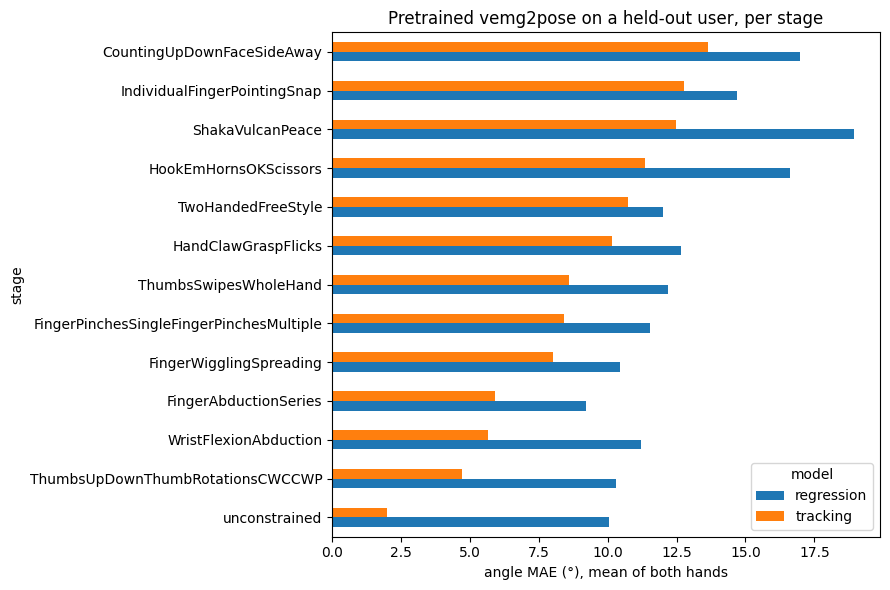

In [11]:
tab = results.pivot_table(index="stage", columns="model", values="angle MAE (°)", aggfunc="mean")
ax = tab.sort_values("tracking").plot.barh(figsize=(9, 6))
ax.set_xlabel("angle MAE (°), mean of both hands")
ax.set_title("Pretrained vemg2pose on a held-out user, per stage")
plt.tight_layout(); plt.show()

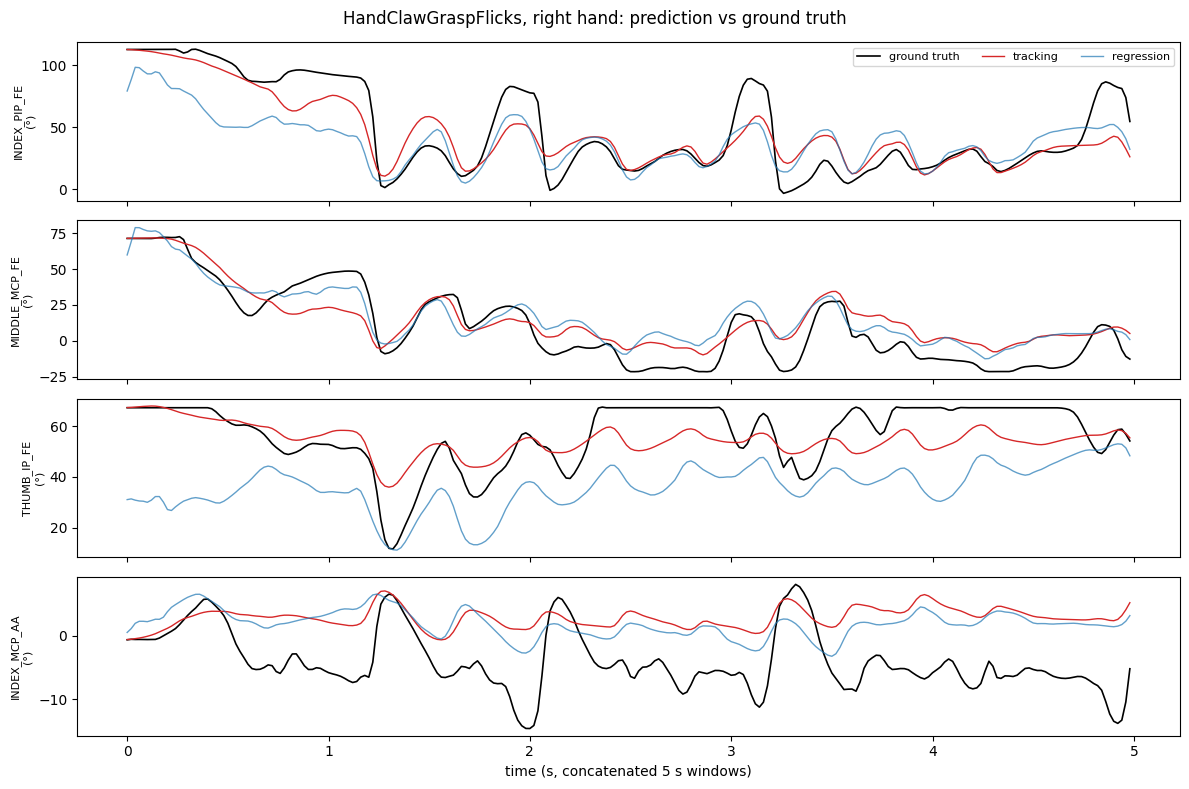

In [12]:
P, Y = predictions[("tracking_vemg2pose", "HandClawGraspFlicks", "right")]
Pr, _ = predictions[("regression_vemg2pose", "HandClawGraspFlicks", "right")]
show = ["INDEX_PIP_FE", "MIDDLE_MCP_FE", "THUMB_IP_FE", "INDEX_MCP_AA"]
t50 = np.arange(len(Y)) / 50
fig, axs = plt.subplots(len(show), 1, figsize=(12, 8), sharex=True)
for ax, n in zip(axs, show):
    j = JOINT_NAMES.index(n)
    ax.plot(t50, np.degrees(Y[:, j]), color="k", lw=1.2, label="ground truth")
    ax.plot(t50, np.degrees(P[:, j]), color="tab:red", lw=1, label="tracking")
    ax.plot(t50, np.degrees(Pr[:, j]), color="tab:blue", lw=1, alpha=0.7, label="regression")
    ax.set_ylabel(f"{n}\n(°)", fontsize=8)
axs[0].legend(ncol=3, fontsize=8)
axs[-1].set_xlabel("time (s, concatenated 5 s windows)")
fig.suptitle("HandClawGraspFlicks, right hand: prediction vs ground truth")
plt.tight_layout(); plt.show()

**Reading it.**
- On a person it has never seen, the **tracking** model is off by ~9° per joint on average (~13 mm per
  landmark), and **regression** by ~13° (~16-17 mm). The gap is the value of knowing where the hand started: EMG
  says much more about *how the hand is moving* than about *where it is* (see `emg_kinematics_encoding.ipynb`).
- Near-static stages (`unconstrained`, thumb tasks of the left hand) look excellent for tracking only because
  the hand barely moves away from the given starting pose: a low error there is not a sign of good decoding.
  Regression has no such shortcut.
- Flexion/extension of the fingers is followed well; abduction (`*_AA`) is much worse (see the per-joint
  numbers in `compression_tolerance.ipynb`).

## 8. Where our project plugs in

```
 direct baseline        sEMG ─► network ─► 64 features ─► decoder ─► ŷ ∈ R^20 ───────────────────────► loss(ŷ, y)

 PCA bottleneck         sEMG ─► network ─► 64 features ─► decoder ─► ẑ ∈ R^k ─► ŷ = μ + Wᵀ ẑ  (fixed) ─► loss(ŷ, y)
                                                                        z = W (y − μ),  W: k × 20, fitted on training poses

 AE bottleneck          sEMG ─► network ─► 64 features ─► decoder ─► ẑ ∈ R^k ─► ŷ = g(ẑ)  (frozen AE decoder) ─► loss(ŷ, y)
```

Shapes for k = 6 and a 5 s window: the decoder output becomes (B, 6, 250) instead of (B, 20, 250); everything
upstream is unchanged. The loss can stay in angle space (so all metrics are comparable).

**A detail that matters for the tracking model.** It predicts *velocities* and integrates them. With PCA this
is free, because PCA is linear: the velocity of the latent equals the latent of the velocity,
$\dot z = W \dot y$, so the decoder can predict $\dot z$ and integrate in latent space. This matters for the
*regression* model too: `regression_vemg2pose` predicts absolute pose only for the first 250 ms and then also
integrates velocities (`VEMG2PoseWithInitialState`). A nonlinear autoencoder can still be used this way (predict
$\dot z$ and integrate), but its latent velocity $\dot z = J_f(y)\,\dot y$ depends on where the hand is (the
Jacobian of the encoder), so the decoder has a harder target to learn. Quick numerical check of the PCA case:

In [13]:
Yall = np.vstack([v[1] for k, v in predictions.items() if k[0] == "tracking_vemg2pose"])
mu = Yall.mean(0)
_, _, Vt = np.linalg.svd(Yall - mu, full_matrices=False)
W = Vt[:6]
y = Y  # one recording at 50 Hz
dz_from_scores = np.gradient((y - mu) @ W.T, axis=0)      # derivative of the PCA scores
z_of_dy = np.gradient(y, axis=0) @ W.T                    # PCA projection of the joint velocities
print("max |d/dt(Wy) - W(dy/dt)| =", np.abs(dz_from_scores - z_of_dy).max(), "(zero up to rounding)")

max |d/dt(Wy) - W(dy/dt)| = 6.106226635438361e-16 (zero up to rounding)


## Summary

| quantity | value |
|---|---|
| input | 16 channels × 2 kHz raw EMG (only 40 Hz high-pass + noise scaling) |
| target | 20 joint angles (radians) at 2 kHz; real content < ~10 Hz |
| window | 11,790 samples = 0.9 s context + 5 s predicted |
| network | conv (256 filters, 16 ch × 5.5 ms) → TDS → 64 features at 25 Hz → LSTM at 50 Hz (~6 M params) |
| output | 20 angles; tracking = integrate predicted velocities from a known start |
| metrics | angle MAE (°) and landmark distance (mm, forward kinematics of a fixed hand) |
| pretrained, held-out mini user | tracking ≈ 9° / 13 mm, regression ≈ 13° / 16-17 mm |
| our change | the decoder predicts k < 20 latent numbers, mapped back to 20 angles by a fixed PCA/AE decoder |